In [1]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from google.cloud import bigquery
from google.oauth2 import service_account
import google.auth
from pathlib import Path

plt.rcParams.update({
    'figure.figsize':   (14, 6),
    'figure.facecolor': 'white',
    'figure.dpi':       100,
    'font.family':      'sans-serif',
    'font.size':        11,
    'axes.titlesize':   13,
    'axes.titleweight': 'bold',
    'axes.facecolor':   '#F8F9FA',
    'axes.grid':        True,
    'axes.spines.top':  False,
    'axes.spines.right':False,
    'grid.color':       '#E0E0E0',
    'grid.linestyle':   '--',
    'grid.alpha':       0.7,
    'savefig.bbox':     'tight',
    'savefig.dpi':      150,
})

COLORS = {
    'primary':   '#2196F3',
    'secondary': '#FF9800',
    'success':   '#4CAF50',
    'danger':    '#F44336',
    'neutral':   '#9E9E9E',
    'purple':    '#9C27B0',
    'teal':      '#009688',
}

ALPHA = 0.05

# BIGQUERY CONNECTION
PROJECT_ID = "olist-ecommerce-analytics-1"
CREDENTIALS_PATH  = "../credentials/bigquery-key.json"
MART = f"{PROJECT_ID}.olist_mart"
REPORTING = f"{PROJECT_ID}.olist_reporting"

def get_bq_client(project_id: str) -> bigquery.Client:

    credentials, _ = google.auth.default(
        scopes=["https://www.googleapis.com/auth/cloud-platform"]
    )

    return bigquery.Client(
        project=project_id,
        credentials=credentials,
    )

def run_query(
    client: bigquery.Client,
    query: str,
) -> pd.DataFrame:

    query_job = client.query(query)

    return query_job.result().to_dataframe()

client = get_bq_client(PROJECT_ID)

print("BigQuery client initialized successfully")
print("complete | α =", ALPHA)

BigQuery client initialized successfully
complete | α = 0.05


In [2]:
# Fact orders
df = run_query(client, f"""
    SELECT
        order_id,
        customer_unique_id,
        purchase_date,
        purchase_year,
        purchase_month,
        purchase_year_month,
        purchase_day_of_week,
        is_revenue_generating,
        is_ontime_delivery,
        is_order_date_anomaly,
        purchase_to_delivery_days,
        delivery_vs_estimated_days,
        total_gmv,
        total_price,
        total_freight_value,
        item_count,
        primary_payment_type,
        max_installments,
        review_score,
        review_sentiment,
        customer_type
    FROM `{MART}.fact_orders`
    WHERE is_revenue_generating = TRUE
      AND is_order_date_anomaly = FALSE
""")

df['purchase_date'] = pd.to_datetime(df['purchase_date'])

df['is_weekend'] = df['purchase_day_of_week'].isin([1, 7])

df['day_type'] = df['is_weekend'].map({
    True: 'Weekend',
    False: 'Weekday'
})


# Items (delivered)
df_items = run_query(client, f"""
    SELECT
        order_id,
        order_item_id,
        product_category_name_english,
        product_super_category,
        customer_state,
        customer_region,
        seller_state,
        price,
        freight_value,
        item_gmv,
        review_score,
        purchase_to_delivery_days,
        primary_payment_type,
        purchase_year_month
    FROM `{MART}.fact_order_items`
    WHERE is_revenue_generating = TRUE
""")


# Display results
print("Data loaded:")
print(f"fact_orders (delivered): {len(df):,} rows")
print(f"fact_order_items: {len(df_items):,} rows")

print(
    f"Date range: {df['purchase_date'].min().date()} -> "
    f"{df['purchase_date'].max().date()}"
)

Data loaded:
fact_orders (delivered): 95,105 rows
fact_order_items: 110,197 rows
Date range: 2016-09-15 -> 2018-08-29


In [3]:
print("FACT ORDERS:")
print(df[[
    'total_gmv',
    'purchase_to_delivery_days',
    'review_score',
    'max_installments'
]].dtypes)

print("\nFACT ORDER ITEMS:")
print(df_items[[
    'price',
    'freight_value'
]].dtypes)

FACT ORDERS:
total_gmv                    object
purchase_to_delivery_days     Int64
review_score                  Int64
max_installments              Int64
dtype: object

FACT ORDER ITEMS:
price            object
freight_value    object
dtype: object


In [4]:
# Fact Orders
df['total_gmv'] = df['total_gmv'].astype('float64')

# Fact Order Items
df_items['price'] = df_items['price'].astype('float64')
df_items['freight_value'] = df_items['freight_value'].astype('float64')

print("FACT ORDERS:")
print(df[[
    'total_gmv',
    'purchase_to_delivery_days',
    'review_score',
    'max_installments'
]].dtypes)

print("\nFACT ORDER ITEMS:")
print(df_items[[
    'price',
    'freight_value'
]].dtypes)

FACT ORDERS:
total_gmv                    float64
purchase_to_delivery_days      Int64
review_score                   Int64
max_installments               Int64
dtype: object

FACT ORDER ITEMS:
price            float64
freight_value    float64
dtype: object


In [5]:
def descriptive_stats(series: pd.Series, name: str) -> pd.Series:
    s = series.dropna()
    return pd.Series({
        'count': len(s),
        'missing': series.isna().sum(),
        'missing_pct': f"{series.isna().mean()*100:.2f}%",
        'mean': round(s.mean(), 4),
        'median': round(s.median(), 4),
        'mode': round(s.mode().iloc[0], 4) if len(s.mode()) > 0 else np.nan,
        'std': round(s.std(), 4),
        'variance': round(s.var(), 4),
        'min': round(s.min(), 4),
        'p5': round(s.quantile(0.05), 4),
        'p25': round(s.quantile(0.25), 4),
        'p75': round(s.quantile(0.75), 4),
        'p95': round(s.quantile(0.95), 4),
        'max': round(s.max(), 4),
        'IQR': round(s.quantile(0.75) - s.quantile(0.25), 4),
        'skewness': round(stats.skew(s), 4),
        'kurtosis': round(stats.kurtosis(s), 4),
        'cv': f"{s.std()/s.mean()*100:.2f}%" if s.mean() != 0 else 'N/A',
    }, name=name)

metrics = {
    'total_gmv': df['total_gmv'],
    'purchase_to_delivery_days':  df['purchase_to_delivery_days'].dropna(),
    'review_score': df['review_score'].dropna(),
    'max_installments': df['max_installments'].dropna(),
    'item_price': df_items['price'],
    'freight_value': df_items['freight_value'],
}

desc_df = pd.DataFrame({
    name: descriptive_stats(series, name)
    for name, series in metrics.items()
})

print("DESCRIPTIVE STATISTICS SUMMARY")
print(desc_df.T.to_string())

print("\n\nSKEWNESS INTERPRETATION:")
for col in desc_df.columns:
    skew_val = float(desc_df.loc['skewness', col])
    if skew_val > 1:
        interp = "Highly right-skewed"
    elif skew_val > 0.5:
        interp = "Moderately right-skewed"
    elif skew_val < -1:
        interp = "Highly left-skewed"
    elif skew_val < -0.5:
        interp = "Moderately left-skewed"
    else:
        interp = "Approximately symmetric"
    print(f"{col:<35}: {skew_val:>6.3f} => {interp}")

DESCRIPTIVE STATISTICS SUMMARY
                            count missing missing_pct      mean  median   mode       std    variance   min     p5    p25     p75      p95       max    IQR skewness  kurtosis       cv
total_gmv                   95105       0       0.00%  159.9499  105.28  77.57  219.2345  48063.7813  9.59  32.38  61.84  176.34  447.864  13664.08  114.5   9.3895  250.3604  137.06%
purchase_to_delivery_days   95097       0       0.00%   12.5576    10.0      7    9.5804     91.7844     0    3.0    7.0    16.0     29.0       210    9.0   3.8262    39.229   76.29%
review_score                94466       0       0.00%    4.1539     5.0      5    1.2861      1.6541     1    1.0    4.0     5.0      5.0         5    1.0   -1.479    0.9454   30.96%
max_installments            48952       0       0.00%    4.7488     4.0      2    2.7387      7.5005     2    2.0    3.0     6.0     10.0        24    3.0   1.0794    1.1669   57.67%
item_price                 110197       0       0.00% 

NORMALITY TEST RESULTS
        variable  n_total  shapiro_p  shapiro_normal  dagostino_p  dagostino_normal  skewness conclusion                             recommended_test
 Order GMV (BRL)    95105        0.0           False          0.0             False    9.3895 NON-NORMAL Non-parametric (Mann-Whitney/Kruskal-Wallis)
   Delivery Days    95097        0.0           False          0.0             False    3.8262 NON-NORMAL Non-parametric (Mann-Whitney/Kruskal-Wallis)
    Review Score    94466        0.0           False          0.0             False   -1.4790 NON-NORMAL Non-parametric (Mann-Whitney/Kruskal-Wallis)
Item Price (BRL)   110197        0.0           False          0.0             False    8.0308 NON-NORMAL Non-parametric (Mann-Whitney/Kruskal-Wallis)
Max Installments    48952        0.0           False          0.0             False    1.0794 NON-NORMAL Non-parametric (Mann-Whitney/Kruskal-Wallis)


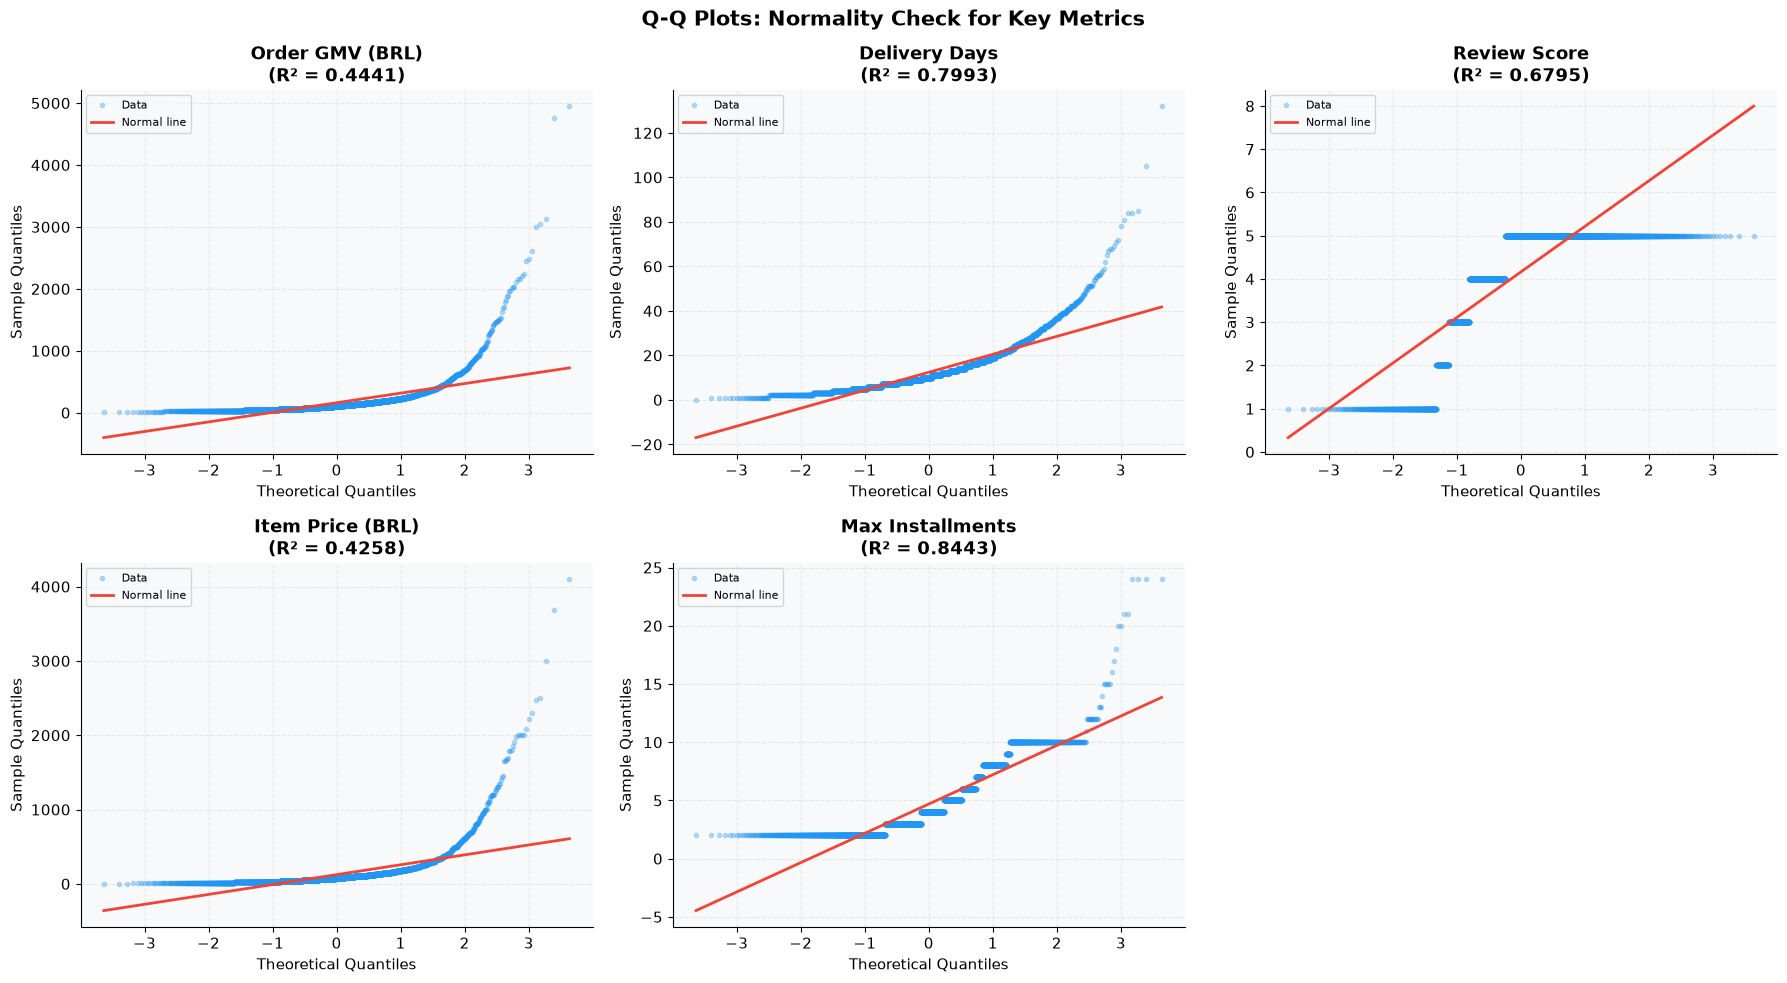

In [ ]:
def test_normality(series: pd.Series, name: str,
                   sample_size: int = 5000) -> dict:
    s = series.dropna()

    if len(s) > sample_size:
        s_sample = s.sample(n=sample_size, random_state=42)
    else:
        s_sample = s

    stat_sw, p_sw = stats.shapiro(s_sample)

    stat_dp, p_dp = stats.normaltest(s)

    return {
        'variable': name,
        'n_total': len(s),
        'n_tested': len(s_sample),
        'shapiro_stat': round(stat_sw, 4),
        'shapiro_p':round(p_sw, 6),
        'shapiro_normal': p_sw >= ALPHA,
        'dagostino_stat': round(stat_dp, 4),
        'dagostino_p': round(p_dp, 6),
        'dagostino_normal': p_dp >= ALPHA,
        'skewness': round(stats.skew(s), 4),
        'kurtosis': round(stats.kurtosis(s), 4),
        'conclusion': 'NORMAL' if p_sw >= ALPHA and p_dp >= ALPHA else 'NON-NORMAL',
        'recommended_test': 'Parametric (T-Test/ANOVA)'
                             if p_sw >= ALPHA and p_dp >= ALPHA
                             else 'Non-parametric (Mann-Whitney/Kruskal-Wallis)'
    }


# Uji normalitas
normality_results = []
test_vars = {
    'Order GMV (BRL)': df['total_gmv'],
    'Delivery Days': df['purchase_to_delivery_days'].dropna(),
    'Review Score': df['review_score'].dropna(),
    'Item Price (BRL)': df_items['price'],
    'Max Installments': df['max_installments'].dropna(),
}

for name, series in test_vars.items():
    result = test_normality(series, name)
    normality_results.append(result)

norm_df = pd.DataFrame(normality_results)

print("NORMALITY TEST RESULTS")
print("=" * 80)
cols_show = ['variable', 'n_total', 'shapiro_p', 'shapiro_normal',
             'dagostino_p', 'dagostino_normal', 'skewness', 'conclusion',
             'recommended_test']
print(norm_df[cols_show].to_string(index=False))

# QQ-PLOTS
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Q-Q Plots: Normality Check for Key Metrics',
             fontsize=15, fontweight='bold')
axes = axes.flatten()

for i, (name, series) in enumerate(test_vars.items()):
    ax = axes[i]
    s  = series.dropna()
    if len(s) > 5000:
        s = s.sample(5000, random_state=42)

    (osm, osr), (slope, intercept, r) = stats.probplot(s, dist="norm")
    ax.plot(osm, osr, 'o', color=COLORS['primary'],
            alpha=0.3, markersize=3, label='Data')
    ax.plot(
        [osm.min(), osm.max()],
        [slope * osm.min() + intercept,
         slope * osm.max() + intercept],
        color=COLORS['danger'], linewidth=2, label='Normal line'
    )
    ax.set_title(f'{name}\n(R² = {r**2:.4f})')
    ax.set_xlabel('Theoretical Quantiles')
    ax.set_ylabel('Sample Quantiles')
    ax.legend(fontsize=8)

if len(test_vars) < len(axes):
    for j in range(len(test_vars), len(axes)):
        axes[j].set_visible(False)

plt.tight_layout()
# plt.savefig('../assets/statistical/01_qq_plots.png')
plt.show()

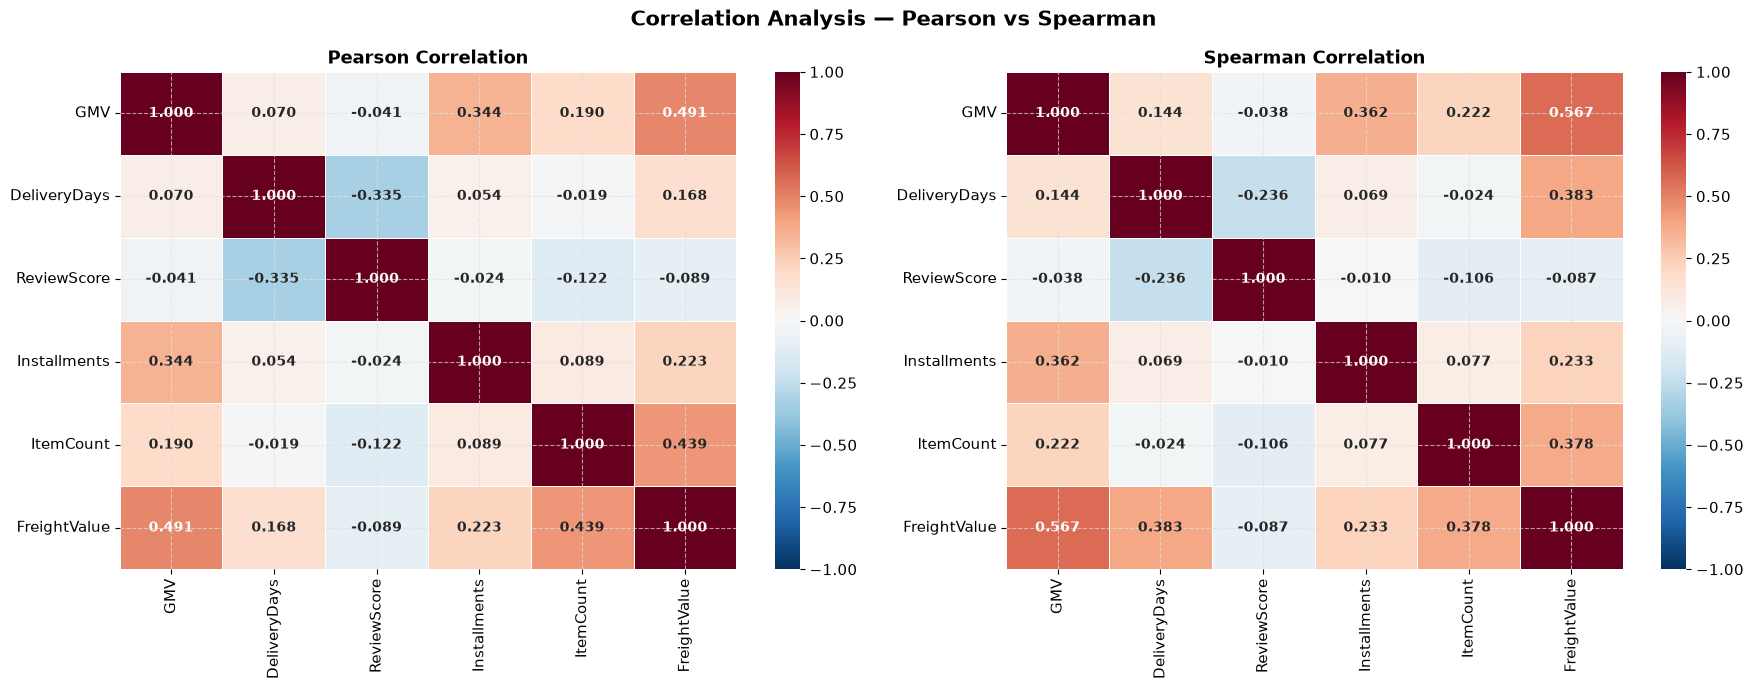

CORRELATION WITH REVIEW SCORE

Variable                Pearson r   Spearman ρ        Strength    Direction      P-value
-------------------------------------------------------------------------------------
DeliveryDays              -0.3352      -0.2361            Weak     Negative            0 ***
   Observations: 94,458
Installments              -0.0243      -0.0102      Negligible     Negative      0.02511 *
   Observations: 48,606
ItemCount                 -0.1220      -0.1060            Weak     Negative   6.319e-234 ***
   Observations: 94,466
GMV                       -0.0412      -0.0384      Negligible     Negative    4.227e-32 ***
   Observations: 94,466
FreightValue              -0.0887      -0.0870      Negligible     Negative    2.95e-158 ***
   Observations: 94,466

Significance: *** p < 0.001 | ** p < 0.01 | * p < 0.05 | ns = not significant


In [11]:
corr_vars = {
    'GMV': df['total_gmv'],
    'DeliveryDays': df['purchase_to_delivery_days'],
    'ReviewScore': df['review_score'],
    'Installments': df['max_installments'],
    'ItemCount': df['item_count'],
    'FreightValue': df['total_freight_value'],
}

corr_df = pd.DataFrame(corr_vars)

corr_df = corr_df.apply(pd.to_numeric, errors='coerce')
corr_df = corr_df.replace([np.inf, -np.inf], np.nan)

pearson_corr = corr_df.corr(method='pearson')
spearman_corr = corr_df.corr(method='spearman')

# HEATMAPS
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

fig.suptitle(
    'Correlation Analysis — Pearson vs Spearman',
    fontsize=15,
    fontweight='bold'
)

heatmap_kws = dict(
    annot=True,
    fmt='.3f',
    linewidths=0.5,
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    annot_kws={'size': 10, 'weight': 'bold'}
)

sns.heatmap(pearson_corr, ax=axes[0], **heatmap_kws)
axes[0].set_title('Pearson Correlation')

sns.heatmap(spearman_corr, ax=axes[1], **heatmap_kws)
axes[1].set_title('Spearman Correlation')

plt.tight_layout()
plt.show()


# FOCUS: REVIEW SCORE CORRELATIONS
print("CORRELATION WITH REVIEW SCORE")
print("=" * 85)

print(
    f"\n{'Variable':<20} {'Pearson r':>12} "
    f"{'Spearman ρ':>12} {'Strength':>15} "
    f"{'Direction':>12} {'P-value':>12}"
)

print("-" * 85)

def corr_strength(r):
    """Interpretasi kekuatan korelasi."""

    if pd.isna(r):
        return 'Undefined'

    r_abs = abs(r)

    if r_abs < 0.10:
        return 'Negligible'
    elif r_abs < 0.30:
        return 'Weak'
    elif r_abs < 0.50:
        return 'Moderate'
    elif r_abs < 0.70:
        return 'Strong'
    else:
        return 'Very Strong'


for var in [
    'DeliveryDays',
    'Installments',
    'ItemCount',
    'GMV',
    'FreightValue'
]:

    # Pairwise deletion: memastikan pasangan observasi sama
    pair = corr_df[['ReviewScore', var]].dropna()

    x = pair['ReviewScore']
    y = pair[var]

    p_r, p_p = stats.pearsonr(x, y) if (
        len(pair) >= 3 and x.nunique() > 1 and y.nunique() > 1
    ) else (np.nan, np.nan)

    sp_r, sp_p = stats.spearmanr(x, y) if (
        len(pair) >= 3 and x.nunique() > 1 and y.nunique() > 1
    ) else (np.nan, np.nan)

    direction = (
        'Positive' if sp_r > 0
        else 'Negative' if sp_r < 0
        else 'Undefined'
    ) if pd.notna(sp_r) else 'Undefined'

    strength = corr_strength(sp_r)

    sig = (
        '***' if sp_p < 0.001
        else '**' if sp_p < 0.01
        else '*' if sp_p < 0.05
        else 'ns' if pd.notna(sp_p)
        else 'N/A'
    )

    print(
        f"{var:<20} {p_r:>12.4f} "
        f"{sp_r:>12.4f} {strength:>15} "
        f"{direction:>12} {sp_p:>12.4g} {sig}"
    )

    print(f"   Observations: {len(pair):,}")

print("\nSignificance: *** p < 0.001 | ** p < 0.01 | * p < 0.05 | ns = not significant")



Metric                            Weekend         Weekday
-------------------------------------------------------
n........................          21,862          73,243
Mean (BRL)...............          158.48          160.39
Median (BRL).............          105.39          105.16
Std Dev (BRL)............          216.81          219.95
Min (BRL)................            9.59           10.07
Max (BRL)................        7,274.88       13,664.08
 Statistic: 1.3492
 p-value: 0.245414
 Equal variances: True Using Student's T-Test

TEST RESULTS:
........................................
Independent T-Test:
 t-statistic: -1.1294
 p-value: 0.258726
 Significant: False (α = 0.05)

   Mann-Whitney U (non-parametric confirmation):
 U-statistic: 797666425
 p-value: 0.407170
 Significant: False

 Effect Size (Cohen's d): -0.0087
 Magnitude: Negligible

 95% CI for difference (Weekend - Weekday):
 [-5.19, 1.38] BRL
 Mean difference: -1.91 BRL


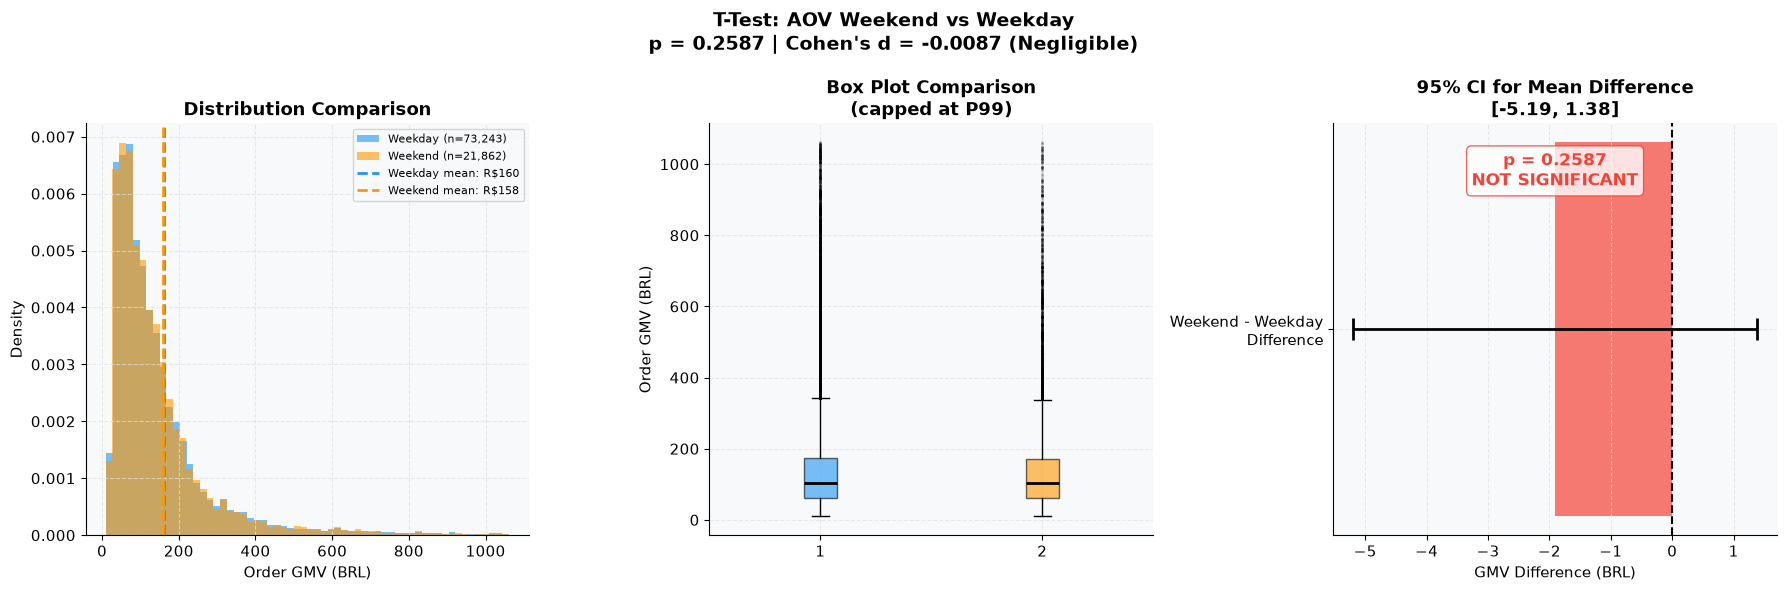

In [16]:
weekend_gmv = df[df['is_weekend'] == True]['total_gmv'].dropna()
weekday_gmv = df[df['is_weekend'] == False]['total_gmv'].dropna()

# DESCRIPTIVE
print(f"\n{'Metric':<25} {'Weekend':>15} {'Weekday':>15}")
print("-" * 55)
print(f"{'n':.<25} {len(weekend_gmv):>15,} {len(weekday_gmv):>15,}")
print(f"{'Mean (BRL)':.<25} {weekend_gmv.mean():>15,.2f} {weekday_gmv.mean():>15,.2f}")
print(f"{'Median (BRL)':.<25} {weekend_gmv.median():>15,.2f} {weekday_gmv.median():>15,.2f}")
print(f"{'Std Dev (BRL)':.<25} {weekend_gmv.std():>15,.2f} {weekday_gmv.std():>15,.2f}")
print(f"{'Min (BRL)':.<25} {weekend_gmv.min():>15,.2f} {weekday_gmv.min():>15,.2f}")
print(f"{'Max (BRL)':.<25} {weekend_gmv.max():>15,.2f} {weekday_gmv.max():>15,.2f}")

# LEVENE TEST
levene_stat, levene_p = stats.levene(weekend_gmv, weekday_gmv)
equal_var = levene_p >= ALPHA
print(f" Statistic: {levene_stat:.4f}")
print(f" p-value: {levene_p:.6f}")
print(f" Equal variances: {equal_var} "
      f"Using {'Student' if equal_var else 'Welch'}'s T-Test")

# INDEPENDENT T-TEST OR WELCH
t_stat, t_p = stats.ttest_ind(
    weekend_gmv, weekday_gmv,
    equal_var=equal_var,
    alternative='two-sided'
)

# MANN-WHITNEY U
mw_stat, mw_p = stats.mannwhitneyu(
    weekend_gmv, weekday_gmv,
    alternative='two-sided'
)

# COHEN'S D
def cohens_d(group1: pd.Series, group2: pd.Series) -> float:
    """
    Menghitung Cohen's d effect size untuk dua grup independen.

    Menggunakan pooled standard deviation.

    Args:
        group1, group2: Dua grup data numerik

    Returns:
        float: Cohen's d value
    """
    n1, n2   = len(group1), len(group2)
    mean_diff = group1.mean() - group2.mean()
    # Pooled std
    pooled_std = np.sqrt(
        ((n1 - 1) * group1.std()**2 + (n2 - 1) * group2.std()**2)
        / (n1 + n2 - 2)
    )
    return mean_diff / pooled_std

d = cohens_d(weekend_gmv, weekday_gmv)

def interpret_cohens_d(d: float) -> str:
    """Interpretasi magnitude Cohen's d."""
    d_abs = abs(d)
    if d_abs < 0.2:  return 'Negligible'
    elif d_abs < 0.5: return 'Small'
    elif d_abs < 0.8: return 'Medium'
    else: return 'Large'

# 95% CONFIDENCE INTERVAL
mean_diff = weekend_gmv.mean() - weekday_gmv.mean()
se_diff   = np.sqrt(
    weekend_gmv.std()**2 / len(weekend_gmv) +
    weekday_gmv.std()**2 / len(weekday_gmv)
)
# Critical t-value for 95% CI
df_ttest = min(len(weekend_gmv), len(weekday_gmv)) - 1
t_crit   = stats.t.ppf(0.975, df=df_ttest)
ci_lower = mean_diff - t_crit * se_diff
ci_upper = mean_diff + t_crit * se_diff

# PRINT RESULTS
print(f"\nTEST RESULTS:")
print(f"{'':.<40}")
print(f"Independent T-Test:")
print(f" t-statistic: {t_stat:.4f}")
print(f" p-value: {t_p:.6f}")
print(f" Significant: {t_p < ALPHA} (α = {ALPHA})")
print(f"\n   Mann-Whitney U (non-parametric confirmation):")
print(f" U-statistic: {mw_stat:.0f}")
print(f" p-value: {mw_p:.6f}")
print(f" Significant: {mw_p < ALPHA}")
print(f"\n Effect Size (Cohen's d): {d:.4f}")
print(f" Magnitude: {interpret_cohens_d(d)}")
print(f"\n 95% CI for difference (Weekend - Weekday):")
print(f" [{ci_lower:,.2f}, {ci_upper:,.2f}] BRL")
print(f" Mean difference: {mean_diff:,.2f} BRL")

# VISUALIZATION
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle(
    f'T-Test: AOV Weekend vs Weekday\n'
    f'p = {t_p:.4f} | Cohen\'s d = {d:.4f} ({interpret_cohens_d(d)})',
    fontsize=14, fontweight='bold'
)

# Plot 1: Distribution comparison
ax1 = axes[0]
p99 = max(weekend_gmv.quantile(0.99), weekday_gmv.quantile(0.99))
ax1.hist(weekday_gmv[weekday_gmv <= p99], bins=60, alpha=0.6,
         color=COLORS['primary'], label=f'Weekday (n={len(weekday_gmv):,})',
         density=True)
ax1.hist(weekend_gmv[weekend_gmv <= p99], bins=60, alpha=0.6,
         color=COLORS['secondary'], label=f'Weekend (n={len(weekend_gmv):,})',
         density=True)
ax1.axvline(weekday_gmv.mean(), color=COLORS['primary'],
            linestyle='--', linewidth=2,
            label=f'Weekday mean: R${weekday_gmv.mean():.0f}')
ax1.axvline(weekend_gmv.mean(), color=COLORS['secondary'],
            linestyle='--', linewidth=2,
            label=f'Weekend mean: R${weekend_gmv.mean():.0f}')
ax1.set_xlabel('Order GMV (BRL)')
ax1.set_ylabel('Density')
ax1.set_title('Distribution Comparison')
ax1.legend(fontsize=8)

# Plot 2: Box plots
ax2 = axes[1]
bp = ax2.boxplot(
    [weekday_gmv[weekday_gmv <= p99],
     weekend_gmv[weekend_gmv <= p99]],
    label=['Weekday', 'Weekend'],
    patch_artist=True,
    medianprops=dict(color='black', linewidth=2),
    flierprops=dict(marker='.', markersize=2, alpha=0.2)
)
bp['boxes'][0].set_facecolor(COLORS['primary'])
bp['boxes'][1].set_facecolor(COLORS['secondary'])
for box in bp['boxes']:
    box.set_alpha(0.6)
ax2.set_ylabel('Order GMV (BRL)')
ax2.set_title('Box Plot Comparison\n(capped at P99)')

# Plot 3: Confidence interval for difference
ax3 = axes[2]
ax3.barh(
    ['Weekend - Weekday\nDifference'],
    [mean_diff],
    xerr=[[mean_diff - ci_lower], [ci_upper - mean_diff]],
    color=COLORS['success'] if mean_diff > 0 else COLORS['danger'],
    alpha=0.7, capsize=8, height=0.4,
    error_kw=dict(linewidth=2, capthick=2)
)
ax3.axvline(0, color='black', linewidth=1.5, linestyle='--')
ax3.set_xlabel('GMV Difference (BRL)')
ax3.set_title(f'95% CI for Mean Difference\n[{ci_lower:.2f}, {ci_upper:.2f}]')

# Annotation
significance = "SIGNIFICANT" if t_p < ALPHA else "NOT SIGNIFICANT"
color_sig    = COLORS['success'] if t_p < ALPHA else COLORS['danger']
ax3.text(
    0.5, 0.85,
    f"p = {t_p:.4f}\n{significance}",
    transform=ax3.transAxes,
    ha='center', fontsize=12, fontweight='bold', color=color_sig,
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor=color_sig)
)

plt.tight_layout()
# plt.savefig('../assets/statistical/03_ttest_aov_weekend_weekday.png')
plt.show()